# Learning Curve 3: Reaching 2000

**Marko Antolčić · NeuralGambit research**

The [learning-curve notebook](learning-curve-1-your-start.ipynb) (section 4) asked one question about a new player's **first 100 games**: will this player ever hold a 2000 blitz rating? This notebook extends that study to the three questions a player below 2000 actually asks, at any point in their career:

1. **Will I reach 2000?** One model per checkpoint (game 100, 200, 300, 500 and 1,000), each using the first 100 games *and* the most recent games, with the predictions recalibrated where that helps.
2. **When?** Survival analysis on the full game history: how many games it took, how often players got there by game N, and a model of the remaining games for players who will get there.
3. **How?** Which habits in the games (sessions, tilt, formats, openings, clock, endings) and off the board (puzzles, studies, other time controls) go with reaching 2000 at the same rating and progress, and whether a player's own changes in habit are followed by faster progress.

It also builds what the [Learning Curve tab](https://www.neuralgambit.com/stats/learning-curve) shows: the chance, the time, similar players and the advice.

**Data.** The 1,117 players analysed in section 4 of the learning-curve notebook (accounts created July 2020 – January 2021, settled start below 1900, no 2000 within 100 games): all 343 who reached 2000 by the earlier rule and 774 random others. The reachers' games were downloaded until they held 2000+ for 30 days (or to the end of their career); the others' to game 1,000, and to the end of their career for those who ever touched 2000. That is about 2.6 million rated blitz games.

In [1]:
import sys, json, shutil, warnings
from pathlib import Path
from datetime import datetime, timezone
ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
try:
    display
except NameError:  # running as a plain script
    display = print

import numpy as np
import pandas as pd
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 80)
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss
from lifelines import KaplanMeierFitter, CoxPHFitter, WeibullAFTFitter

from pipeline.common import DATA, OUT
from pipeline.features import SKIP, trend_per_window, entropy
from pipeline.curves import curve, axes, CURVE_END
from pipeline.s09_later_games import ReachTracker, analysed_players

FIG = OUT / "fig"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
BLUE, GREEN, ORANGE, GREY, RED, PURPLE = "#2b6cb0", "#629924", "#d97706", "#8a8f98", "#c53030", "#6b46c1"
def save(name): plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

LEVEL, HOLD_DAYS = 2000, 30
LANDMARKS = [100, 200, 300, 500, 1000]
SPEC = json.loads((OUT / "curves.json").read_text())       # curve-type centres from the learning-curve notebook
TYPE_DUMMIES = ["Fast starter", "Late climber", "Declining"]   # vs Holding steady

import os
full = pd.read_parquet(DATA / os.environ.get("REACH_FULL", "full.parquet"))   # REACH_FULL: a small test file
by = {p: g.reset_index(drop=True) for p, g in full.groupby("player", observed=True)}
players = analysed_players().set_index("id").loc[list(by)]
print(f"{len(by):,} players, {len(full):,} games ({full.end_phase.ge(0).sum():,} replayed for the game phase)")

1,117 players, 2,589,570 games (1,402,681 replayed for the game phase)


## 0. Who reached 2000, and at which game?

**The rule.** A blitz rating of 2000 or more (not exactly 2000) that doesn't drop below 2000 for 30 days. The rating stays the same between games, so a player who reaches 2000 and stops playing for a month has held it.

The earlier study used the highest rating ever (from the Lichess performance page) and checked only the month around that peak. Following each player game by game changes the label for a few players:

- players whose peak was 2100+ but who **never held** 2000 for 30 days (the earlier rule counted any 2100+ peak as held),
- players who held 2000 **at another time** than the month around their peak.

The game number where the 30-day stretch began is the **"when"**.

In [2]:
NOW = datetime.now(timezone.utc)
from pipeline.s09_later_games import latest_records
REC = latest_records().set_index("id")
last_game = pd.read_json(DATA / "last_game.ndjson", lines=True, convert_dates=False).drop_duplicates("id", keep="last").set_index("id")
rows = []
for pid, g in by.items():
    p = players.loc[pid]
    tr = ReachTracker()
    for ts, r in zip(g.ts, g.rating_after):
        if tr.add(ts.to_pydatetime(), int(r)):
            break
    rec = REC.loc[pid]
    # downloaded to the end of the career (the step-9 counter also saw games without a rating change, which are dropped here)
    complete = bool(rec.games_seen >= p.rated - 5 or rec.get("continued") == True)
    if tr.held is None and pd.notna(rec.held_idx):
        # step 9 confirmed the hold on a game that has no rating change (dropped from this table); time at 2000+ still counts
        tr.held = (int(rec.held_idx), pd.Timestamp(rec.held_date).to_pydatetime())
    if tr.held is None and complete:
        tr.finish(NOW)
    rows.append({"id": pid, "username": p.username, "weight": p.weight, "old_label": bool(p.reached),
                 "reached": tr.held is not None, "held_game": tr.held[0] if tr.held else np.nan,
                 "held_date": tr.held[1] if tr.held else pd.NaT,
                 "touch_game": tr.touch[0] if tr.touch else np.nan,
                 "career_games": int(p.rated), "downloaded": len(g), "complete": complete, "peak": p.peak,
                 "first_ts": g.ts.iloc[0], "last_ts": g.ts.iloc[-1]})
P = pd.DataFrame(rows).set_index("id")
P["unresolved"] = ~P.reached & ~P.complete & (P.peak >= LEVEL)   # touched 2000 later than we followed them
lg = pd.to_datetime(last_game.reindex(P.index).last_date, utc=True, format="mixed", errors="coerce")
P["last_date"] = lg.fillna(P.last_ts).where(~P.complete, P.last_ts)
y_all, w_all = P.reached.astype(int).to_numpy(), P.weight.to_numpy()

display(pd.crosstab(P.old_label.map({True: "reached (earlier rule)", False: "not (earlier rule)"}),
                    P.reached.map({True: "reached (game by game)", False: "not (game by game)"})))
print(f"Unresolved (touched 2000 after the games followed so far): {P.unresolved.sum()}")
print(f"Weighted share who reached 2000: {np.average(y_all, weights=w_all):.2%} (earlier rule {np.average(P.old_label, weights=w_all):.2%})")
P[["reached", "held_game", "unresolved"]].to_csv(DATA / "reach_labels.csv")   # used by section 4 of the learning-curve notebook
R = P[P.reached]
print(f"Held from game: median {R.held_game.median():,.0f}, middle 50% {R.held_game.quantile(.25):,.0f}–{R.held_game.quantile(.75):,.0f}; "
      f"first touch of 2000: median game {R.touch_game.median():,.0f}")

reached,not (game by game),reached (game by game)
old_label,,
not (earlier rule),758,16
reached (earlier rule),21,322


Unresolved (touched 2000 after the games followed so far): 0
Weighted share who reached 2000: 6.50% (earlier rule 4.83%)
Held from game: median 2,186, middle 50% 979–4,224; first touch of 2000: median game 1,013


**Reading the result.** Following every game changed the label for 37 of 1,117 players. 21 earlier "reachers" peaked at 2000+ but never stayed there for 30 days. 16 earlier controls did hold 2000, most of them only after game 1,000 (one after 17,000 games). Because each control counts about 8.7 times, the weighted share who reached 2000 rises from 4.8% to 6.5%. Every player was followed until the hold or the end of their career, so no label is left open.

## 1. Will I reach 2000? Landmark models

A player with 450 games who hasn't reached 2000 is a different case from a new player: the early games still matter, but so does where the rating is now and where it has been heading. A **landmark model** handles this with one model per checkpoint (100, 200, 300, 500 and 1,000 games). Each is fitted only on players who, at that checkpoint, **were still playing, had not yet held 2000 and were rated below 2000**, and predicts whether they ever held it. Players who stopped before the checkpoint are not in that model, and players who got there earlier are not either.

Inputs at checkpoint *L*:

- **start**: the settled starting rating (mean of games 30–39),
- **early trend**: the rating trend over games 30–99 (Elo per 100 games),
- **current**: the mean rating over the last 10 games before *L*,
- **recent trend**: the trend over the last *N* games before *L* (N chosen below),
- from game 300: the **curve type** (from the learning-curve notebook).

The page uses the checkpoint at or below the player's game count, with the player's current rating and recent trend.

The sample is case–control (all reachers, about 1 in 9 others), so every rate and probability is weighted back to the cohort: each control counts about 8.7 times. Five-fold cross-validation, repeated 5 times.

In [3]:
def curve_type(r):
    gain, bend = axes(curve(r))
    z = np.array([gain / SPEC["axis_sd"][0], bend / SPEC["axis_sd"][1]])
    return SPEC["types"][int(np.argmin([np.sum((z - np.array(t["centre"])) ** 2) for t in SPEC["types"]]))]["name"]

def at_landmark(g, L, n_recent):
    """Features at checkpoint L from games [0, L)."""
    r = g.rating_after.to_numpy(dtype=float)[:L]
    f = {"start": r[SKIP:SKIP + 10].mean(), "early_trend": trend_per_window(r[SKIP:100])[0],
         "current": r[-10:].mean(), "peak_gap": r[SKIP:].max() - r[-10:].mean()}
    for n in n_recent:
        f[f"recent_{n}"] = trend_per_window(r[max(SKIP, L - n):])[0]
    w = g.iloc[max(0, L - 100):L]
    f["games_per_week"] = len(w) / max((w.ts.iloc[-1] - w.ts.iloc[0]).total_seconds() / 604800, 1 / 7)
    if L >= CURVE_END:
        f["type"] = curve_type(r[:CURVE_END])
    return f

N_RECENT = [50, 100, 200]
TOL = 15   # a few games per player have no rating change and were dropped; allow a short shortfall at the checkpoint
LM = {}
for L in LANDMARKS:
    rows = []
    for pid, g in by.items():
        p = P.loc[pid]
        if p.career_games < L or len(g) < L - TOL:
            continue                                  # stopped before the checkpoint
        if p.reached and p.held_game <= L:
            continue                                  # already there
        Lr = min(L, len(g))
        if g.rating_after.iloc[Lr - 1] >= LEVEL:
            continue                                  # at 2000+ right now, not yet held
        rows.append({"id": pid, **at_landmark(g, Lr, [n for n in N_RECENT if n <= L - SKIP] or [L - SKIP])})
    d = pd.DataFrame(rows).set_index("id").join(P[["reached", "weight", "held_game", "career_games", "username", "unresolved"]])
    LM[L] = d
pd.DataFrame({L: {"players at risk": len(d), "reached later": int(d.reached.sum()),
                  "weighted rate": f"{np.average(d.reached, weights=d.weight):.1%}"} for L, d in LM.items()}).T

,players at risk,reached later,weighted rate
100,1115,338,6.5%
200,1039,317,6.7%
300,984,301,6.8%
500,896,277,7.0%
1000,737,230,7.2%


In [4]:
def wlogit(C=1.0): return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000))
def wgb(): return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=0)

def oof(X, y, w, mk, reps=5):
    """Out-of-fold predictions (mean over repeats) plus mean weighted ROC-AUC, PR-AUC and log loss over repeats."""
    P_, aucs, aps, lls = np.zeros(len(y)), [], [], []
    for rep in range(reps):
        p = np.zeros(len(y))
        for tr, te in StratifiedKFold(5, shuffle=True, random_state=rep).split(X, y):
            m = mk()
            kw = {"logisticregression__sample_weight": w[tr]} if hasattr(m, "steps") else {"sample_weight": w[tr]}
            p[te] = m.fit(X.iloc[tr], y[tr], **kw).predict_proba(X.iloc[te])[:, 1]
        aucs.append(roc_auc_score(y, p, sample_weight=w)); aps.append(average_precision_score(y, p, sample_weight=w))
        lls.append(log_loss(y, np.clip(p, 1e-6, 1 - 1e-6), sample_weight=w)); P_ += p / reps
    return P_, np.mean(aucs), np.mean(aps), np.mean(lls)

def design(d, cols):
    X = d[[c for c in cols if c != "type"]].astype(float)
    if "type" in cols:
        X = X.join(pd.DataFrame({t: (d.type == t).astype(float) for t in TYPE_DUMMIES}, index=d.index))
    return X

res = []
for L, d in LM.items():
    y, w = d.reached.astype(int).to_numpy(), d.weight.to_numpy()
    recents = [c for c in d.columns if c.startswith("recent_")]
    sets = {"start + early trend": ["start", "early_trend"], "+ current rating": ["start", "early_trend", "current"]}
    for rc in recents:
        sets[f"+ current + {rc.replace('_', ' ')}"] = ["start", "early_trend", "current", rc]
    if L >= CURVE_END:
        sets["+ current + recent 100 + type"] = ["start", "early_trend", "current", "recent_100", "type"]
    for name, cols in sets.items():
        _, auc, ap, ll = oof(design(d, cols), y, w, wlogit)
        res.append({"checkpoint": L, "inputs": name, "ROC-AUC": auc, "PR-AUC": ap, "log loss": ll})
    best_lin = ["start", "early_trend", "current", "recent_100" if "recent_100" in d else recents[-1]]
    _, auc, ap, ll = oof(design(d, best_lin), y, w, wgb)
    res.append({"checkpoint": L, "inputs": "same, gradient boosting", "ROC-AUC": auc, "PR-AUC": ap, "log loss": ll})
lm_cv = pd.DataFrame(res).set_index(["checkpoint", "inputs"]).round(3)
lm_cv

ROC-AUC  PR-AUC  log loss
checkpoint inputs                                                  
100        start + early trend              0.874   0.519     0.168
           + current rating                 0.874   0.519     0.168
           + current + recent 50            0.873   0.513     0.169
           same, gradient boosting          0.869   0.461     0.176
200        start + early trend              0.866   0.478     0.176
           + current rating                 0.884   0.498     0.168
           + current + recent 50            0.883   0.494     0.169
           + current + recent 100           0.885   0.498     0.167
           same, gradient boosting          0.858   0.469     0.186
300        start + early trend              0.863   0.495     0.180
           + current rating                 0.902   0.475     0.162
           + current + recent 50            0.902   0.470     0.163
           + current + recent 100           0.902   0.474     0.163
           + current + recent 200           0.905   0.455     0.162
           + current + recent 100 + type    0.900   0.487     0.163
           same, gradient boosting          0.884   0.504     0.175
500        start + early trend              0.854   0.475     0.187
           + current rating                 0.917   0.524     0.155
           + current + recent 50            0.917   0.519     0.155
           + current + recent 100           0.917   0.530     0.154
           + current + recent 200           0.916   0.519     0.156
           + current + recent 100 + type    0.917   0.530     0.155
           same, gradient boosting          0.905   0.527     0.172
1000       start + early trend              0.850   0.449     0.193
           + current rating                 0.924   0.527     0.155
           + current + recent 50            0.923   0.521     0.155
           + current + recent 100           0.924   0.525     0.155
           + current + recent 200           0.923   0.526     0.156
           + current + recent 100 + type    0.923   0.535     0.156
           same, gradient boosting          0.907   0.483     0.185

**Choosing the inputs.** The table compares, at each checkpoint, the earlier two-input model with the current rating and a recent trend over the last 50, 100 or 200 games. The page needs one rule for all checkpoints, so the choice is the recent window that does best on average (log loss is the main measure: it rewards good probabilities, not just a good ranking).

In [5]:
MODEL_COLS = {}
for L, d in LM.items():
    recents = [c for c in d.columns if c.startswith("recent_")]
    MODEL_COLS[L] = ["start", "early_trend", "current"] + (["recent_100"] if "recent_100" in recents else [])
avg = lm_cv.reset_index()
avg = avg[avg.checkpoint >= 200].groupby("inputs")[["ROC-AUC", "log loss"]].mean().sort_values("log loss")
display(avg.round(3))
print("Exported inputs per checkpoint:", MODEL_COLS)

,ROC-AUC,log loss
inputs,,
+ current + recent 100 + type,0.913,0.158
+ current + recent 200,0.915,0.158
+ current + recent 100,0.907,0.160
+ current rating,0.907,0.160
+ current + recent 50,0.906,0.160
"same, gradient boosting",0.889,0.180
start + early trend,0.858,0.184


Exported inputs per checkpoint: {100: ['start', 'early_trend', 'current'], 200: ['start', 'early_trend', 'current', 'recent_100'], 300: ['start', 'early_trend', 'current', 'recent_100'], 500: ['start', 'early_trend', 'current', 'recent_100'], 1000: ['start', 'early_trend', 'current', 'recent_100']}


### Recalibrating the high predictions

The earlier model was well calibrated up to about 25% but too cautious above it (predicted 58%, observed 81%). An **isotonic regression** on the out-of-fold predictions maps each raw prediction to the observed rate, keeping the order. It is checked by **cross-fitting**: the map is learned on four fifths of the players and tested on the fifth.

,ROC-AUC,PR-AUC,"Brier, raw","Brier, recalibrated","calibration error, raw","calibration error, recalibrated",recalibration used
checkpoint,,,,,,,
100,0.8742,0.5185,0.0443,0.0441,0.0217,0.0128,True
200,0.8851,0.4984,0.0451,0.0467,0.0185,0.0242,False
300,0.9020,0.4737,0.0452,0.0471,0.0112,0.0163,False
500,0.9167,0.5301,0.0431,0.0448,0.0116,0.0132,False
1000,0.9235,0.5255,0.0450,0.0475,0.0129,0.0093,False


p_raw                      p_cal                 
               predicted observed players predicted observed players
b                                                                   
(-0.001, 0.01]     0.003    0.007  1751.0     0.004    0.006  1724.0
(0.01, 0.03]       0.018    0.018   593.0     0.022    0.029   615.0
(0.03, 0.1]        0.059    0.047   676.0     0.051    0.047   879.0
(0.1, 0.25]        0.165    0.135   576.0     0.174    0.221   439.0
(0.25, 0.5]        0.349    0.351   686.0     0.338    0.271   447.0
(0.5, 1.0]         0.607    0.695   489.0     0.724    0.638   667.0

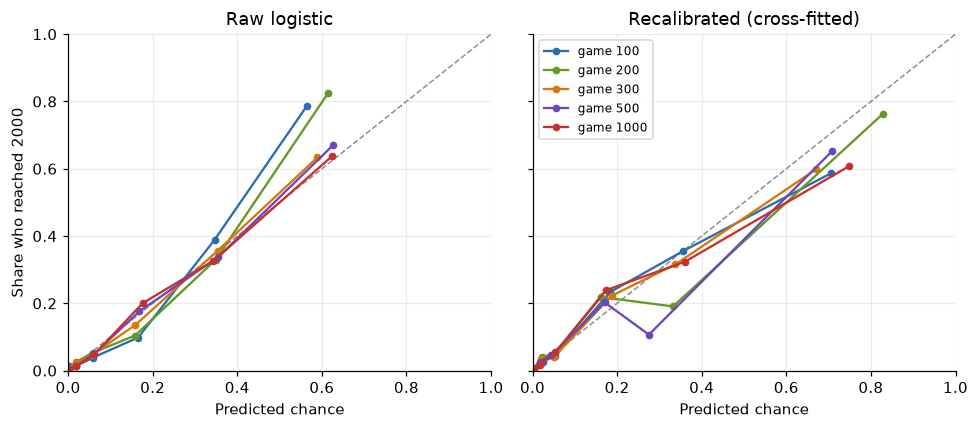

In [6]:
def calib_table(p, y, w, bins=(0, .01, .03, .1, .25, .5, 1)):
    b = pd.cut(p, bins, include_lowest=True)
    d = pd.DataFrame({"p": p, "y": y, "w": w, "b": b})
    return d.groupby("b", observed=True).apply(lambda g: pd.Series({
        "predicted": np.average(g.p, weights=g.w), "observed": np.average(g.y, weights=g.w), "players": len(g)}))

def wece(p, y, w, bins=10):
    q = pd.qcut(p, bins, labels=False, duplicates="drop")
    d = pd.DataFrame({"p": p, "y": y, "w": w, "q": q})
    g = d.groupby("q").apply(lambda g: pd.Series({"gap": abs(np.average(g.p, weights=g.w) - np.average(g.y, weights=g.w)), "w": g.w.sum()}))
    return float(np.average(g.gap, weights=g.w))

FINAL, CAL_ROWS = {}, []
for L, d in LM.items():
    y, w = d.reached.astype(int).to_numpy(), d.weight.to_numpy()
    X = design(d, MODEL_COLS[L])
    p_raw, auc, ap, _ = oof(X, y, w, wlogit)
    p_cal = np.zeros(len(y))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=42).split(X, y):
        iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_raw[tr], y[tr], sample_weight=w[tr])
        p_cal[te] = iso.predict(p_raw[te])
    iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p_raw, y, sample_weight=w)
    model = wlogit().fit(X, y, logisticregression__sample_weight=w)
    FINAL[L] = {"model": model, "iso": iso, "cols": list(X.columns), "auc": auc, "ap": ap, "p_raw": p_raw, "p_cal": p_cal}
    brier = lambda p: np.average((p - y) ** 2, weights=w)
    FINAL[L]["use_iso"] = bool(brier(p_cal) < brier(p_raw))   # keep the recalibration only where it helps on unseen players
    CAL_ROWS.append({"checkpoint": L, "ROC-AUC": auc, "PR-AUC": ap, "Brier, raw": brier(p_raw), "Brier, recalibrated": brier(p_cal),
                     "calibration error, raw": wece(p_raw, y, w), "calibration error, recalibrated": wece(p_cal, y, w),
                     "recalibration used": FINAL[L]["use_iso"]})
display(pd.DataFrame(CAL_ROWS).set_index("checkpoint").round(4))

fig, axs = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, key, title in zip(axs, ["p_raw", "p_cal"], ["Raw logistic", "Recalibrated (cross-fitted)"]):
    ax.plot([0, 1], [0, 1], color=GREY, lw=1, ls="--")
    for L, col in zip(LANDMARKS, [BLUE, GREEN, ORANGE, PURPLE, RED]):
        d = LM[L]
        ct = calib_table(FINAL[L][key], d.reached.astype(int).to_numpy(), d.weight.to_numpy())
        ax.plot(ct.predicted, ct.observed, "o-", color=col, label=f"game {L}", ms=4)
    ax.set(title=title, xlabel="Predicted chance", xlim=(0, 1), ylim=(0, 1))
axs[0].set_ylabel("Share who reached 2000"); axs[1].legend(fontsize=8)
save("reach-calibration-landmarks")
# all checkpoints pooled: raw vs cross-fitted recalibration
_y = np.concatenate([LM[L].reached.astype(int).to_numpy() for L in LANDMARKS]); _w = np.concatenate([LM[L].weight.to_numpy() for L in LANDMARKS])
pd.concat({k: calib_table(np.concatenate([FINAL[L][k] for L in LANDMARKS]), _y, _w) for k in ["p_raw", "p_cal"]}, axis=1).round(3)

### What the inputs do

Odds ratios per standard deviation at each checkpoint (from the fitted logistic models, before recalibration).

In [7]:
orows = {}
for L, f in FINAL.items():
    sc, lr = f["model"][0], f["model"][-1]
    orows[L] = {c: float(np.exp(b)) for c, b in zip(f["cols"], lr.coef_[0])}
    orows[L].update({f"SD of {c}": float(s) for c, s in zip(f["cols"], sc.scale_)})
pd.DataFrame(orows).round(2)

,100,200,300,500,1000
start,2.88,3.12,0.29,0.29,0.54
early_trend,1.83,1.44,0.82,0.87,1.05
current,3.16,3.67,48.09,62.47,42.78
SD of start,332.63,328.34,324.19,321.76,316.36
SD of early_trend,130.09,119.28,118.61,109.81,111.84
SD of current,345.25,338.47,329.88,316.20,297.96
recent_100,NaN,1.67,0.94,0.81,0.85
SD of recent_100,NaN,70.77,67.26,62.21,62.27


**Reading the result.**

- **The current rating is what was missing.** At game 100 it adds little to the start and early trend (ROC-AUC 0.874 at both). From game 200 on it is the main input: at game 1,000 the old two-input model scores 0.850, and adding the current rating lifts it to 0.924. Once the current rating is in (odds ratio about 43–62 per SD from game 300 on), the starting rating turns around: at the same current rating, a *lower* start is the better sign (odds ratio about 0.3–0.5 per SD), because it means a faster climb so far. What counts is where you are and how you got there.
- **The recent trend adds almost nothing** beyond the current rating, whether over 50, 100 or 200 games (differences in the third decimal). It is kept at 100 games because players expect it and it costs nothing; the curve type adds nothing either. Gradient boosting does slightly worse than the logistic model.
- **Calibration.** The earlier first-100-games model was too cautious above 25%. With the current rating in, the raw model is already close: the isotonic recalibration improves the probabilities on unseen players only at game 100, so the page uses it only there. Pooled over the checkpoints, a predicted 35% meant 35 in 100 got there; above 50% the raw model is still a little cautious (predicted 61%, observed 70%).
- **The ranking is good, the probabilities are wide.** ROC-AUC about 0.87–0.92 at every checkpoint, but PR-AUC around 0.5: among players given a high chance, roughly half still don't get there.

## 2. When? Survival analysis

**Why survival analysis.** A yes/no model throws away *when*, and it can't use players who are still on their way. Survival methods use the time to the event (here, the game number where the 30-day hold began) and treat players who haven't got there as **censored**: we know only that they hadn't reached it by their last game.

Three methods, each for a different job:

- **Kaplan–Meier** draws the picture: the share who had reached 2000 by game N.
- **Cox regression** measures which early factors speed it up, without assuming a shape for the timing.
- **Weibull regression** (accelerated failure time) gives the number on the page: how many more games a player who will get there is likely to need.

**Censoring and quitting.** Kaplan–Meier assumes that players who stop are like those who carry on. Quitting is not like that: players who stop rarely come back and reach 2000. So the main curve is the **cumulative incidence** (the share of all players who had reached it by game N, with quitting counted as never reaching), and Kaplan–Meier is shown next to it as the "if everyone kept playing" upper bound.

,by game 500,"by game 1,000","by game 2,000","by game 5,000","by game 10,000"
<1300,0.1%,0.1%,0.4%,1.0%,1.0%
1300–1500,0.1%,1.2%,2.1%,2.7%,4.7%
1500–1700,0.5%,1.2%,2.7%,5.1%,6.1%
1700–1900,3.4%,10.7%,19.1%,29.4%,35.1%


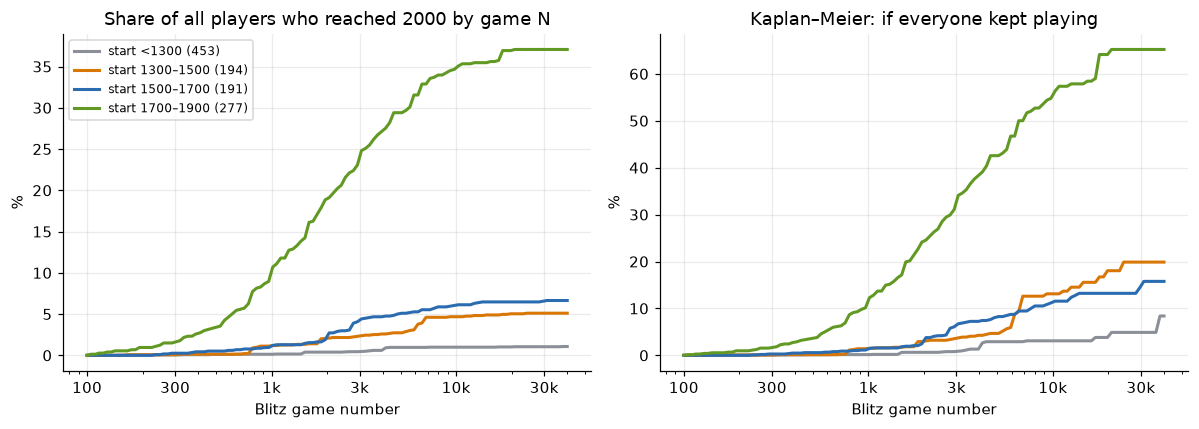

In [8]:
T = P.assign(T=np.where(P.reached, P.held_game, P.career_games).astype(float), E=P.reached.astype(int))
T = T.join(LM[100][["start", "early_trend", "games_per_week"]], how="inner")
T["start band"] = pd.cut(T.start, [0, 1300, 1500, 1700, 1900], labels=["<1300", "1300–1500", "1500–1700", "1700–1900"])
grid = np.unique(np.round(np.geomspace(100, 40000, 120)))

def cum_incidence(d):
    return np.array([d.weight[(d.E == 1) & (d["T"] <= n)].sum() / d.weight.sum() for n in grid])

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ci_tab = {}
for band, col in zip(T["start band"].cat.categories, [GREY, ORANGE, BLUE, GREEN]):
    d = T[T["start band"] == band]
    ci = cum_incidence(d); ci_tab[band] = ci
    axs[0].plot(grid, ci * 100, color=col, lw=2, label=f"start {band} ({len(d)})")
    km = KaplanMeierFitter().fit(d["T"], d.E, weights=d.weight)
    axs[1].plot(grid, (1 - km.survival_function_at_times(grid).to_numpy()) * 100, color=col, lw=2, label=f"start {band}")
for ax, t in zip(axs, ["Share of all players who reached 2000 by game N", "Kaplan–Meier: if everyone kept playing"]):
    ax.set(xscale="log", title=t, xlabel="Blitz game number", ylabel="%")
    ax.set_xticks([100, 300, 1000, 3000, 10000, 30000], ["100", "300", "1k", "3k", "10k", "30k"])
axs[0].legend(fontsize=8)
save("reach-when-incidence")
pd.DataFrame({b: {f"by game {n:,}": f"{100 * ci_tab[b][np.searchsorted(grid, n)]:.1f}%" for n in [500, 1000, 2000, 5000, 10000]}
              for b in ci_tab}).T

### Cox regression: what speeds it up

Time = game number at the hold, censored at the career game count. Inputs from the first 100 games, standardised. Weighted back to the cohort, with robust standard errors. A hazard ratio of 2 means that, at any game count, a player with one SD more of that input was twice as likely to reach 2000 at that point.

In [9]:
C = T[["T", "E", "weight", "start", "early_trend", "games_per_week"]].copy()
C["games_per_week"] = np.log(C.games_per_week)
for c in ["start", "early_trend", "games_per_week"]:
    C[c] = (C[c] - C[c].mean()) / C[c].std()
cph = CoxPHFitter().fit(C, "T", "E", weights_col="weight", robust=True)
display(cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
        .rename(columns={"exp(coef)": "hazard ratio per SD"}).round(3))
print(f"Concordance: {cph.concordance_index_:.3f}. games_per_week is the log of the pace in the first 100 games.")

,hazard ratio per SD,exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
start,6.610,4.149,10.533,0.000
early_trend,2.289,1.820,2.878,0.000
games_per_week,0.749,0.621,0.903,0.002


Concordance: 0.808. games_per_week is the log of the pace in the first 100 games.


### Weibull regression: how many more games

For the page: of the players at checkpoint *L* who later held 2000, how many more games did it take? A Weibull model of the remaining games, with the gap to 2000 (2000 minus the current rating), the recent trend and the early trend as inputs. It is fitted only on players who got there, so it answers "*if* you get there, how long", and the page shows it next to the chance.

The same model on **days** instead of games, with the pace (games per week) as an extra input, gives the time in months.

The check: on players the model never saw (5-fold), how often the real number of games falls inside the predicted middle 50%? It should be close to 50%.

In [10]:
WEIB, wrows = {}, []
for L, d in LM.items():
    rc = "recent_100" if "recent_100" in d else [c for c in d.columns if c.startswith("recent_")][-1]
    rch = d[d.reached & ~d.held_game.isna()].copy()
    rch["more_games"] = rch.held_game - L
    hd = P.held_date.reindex(rch.index)
    lm_date = pd.Series({pid: by[pid].ts.iloc[min(L, len(by[pid])) - 1] for pid in rch.index})
    rch["more_days"] = (hd - lm_date).dt.total_seconds() / 86400
    rch = rch[(rch.more_games > 0) & (rch.more_days > 0)]
    X = pd.DataFrame({"gap": LEVEL - rch.current, "recent": rch[rc], "early_trend": rch.early_trend,
                      "log_pace": np.log(rch.games_per_week)}, index=rch.index)
    out = {}
    for target, cols in [("more_games", ["gap", "recent", "early_trend"]), ("more_days", ["gap", "recent", "early_trend", "log_pace"])]:
        D = X[cols].assign(T=rch[target], w=rch.weight)
        cover, ape = [], []
        for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(D, np.zeros(len(D))):
            m = WeibullAFTFitter().fit(D.iloc[tr], "T", weights_col="w")
            q25 = m.predict_percentile(D.iloc[te], p=0.75)    # lifelines: p = survival probability
            q75 = m.predict_percentile(D.iloc[te], p=0.25)
            med = m.predict_median(D.iloc[te])
            t = D.iloc[te]["T"]
            cover.append(((t >= q25) & (t <= q75)).mean()); ape.append((np.abs(np.log(t / med))).median())
        m = WeibullAFTFitter().fit(D, "T", weights_col="w")
        out[target] = {"model": m, "cols": cols, "coverage": float(np.mean(cover)), "median_abs_log": float(np.mean(ape))}
        wrows.append({"checkpoint": L, "time in": target.split("_")[1], "players": len(D),
                      "median observed": float(D["T"].median()),
                      "middle-50% coverage": np.mean(cover), "typical error (×)": float(np.exp(np.mean(ape)))})
    WEIB[L] = {"recent_col": rc, **out}
pd.DataFrame(wrows).set_index(["checkpoint", "time in"]).round(2)

players  median observed  middle-50% coverage  typical error (×)
checkpoint time in                                                                  
100        games        338          2085.50                 0.53               2.15
           days         338           313.94                 0.58               1.71
200        games        317          2156.00                 0.53               2.12
           days         317           315.60                 0.56               1.70
300        games        301          2150.00                 0.50               2.27
           days         301           305.50                 0.55               1.72
500        games        277          2347.00                 0.52               2.17
           days         277           290.64                 0.56               1.70
1000       games        230          2122.50                 0.52               2.05
           days         230           259.99                 0.51               1.76

In [11]:
display(WEIB[300]["more_games"]["model"].summary[["exp(coef)", "p"]].round(4))
print("exp(coef) > 1 means more games needed per unit of the input (gap in Elo, trends in Elo per 100 games).")

exp(coef)       p
param   covariate                     
lambda_ early_trend     1.0007  0.2762
        gap             1.0014  0.0000
        recent          0.9981  0.0449
        Intercept    2479.5833  0.0000
rho_    Intercept       0.9489  0.1508

exp(coef) > 1 means more games needed per unit of the input (gap in Elo, trends in Elo per 100 games).


**Reading the result.**

- **It takes long.** Players who got there held 2000 from a median of about **game 2,200** (middle half roughly 980–4,200), and first touched it around game 1,000: on average it took over a thousand more games to *stay* there.
- **The starting rating sets the ceiling of the curves.** By game 10,000, about 35% of players who settled at 1700–1900 had held 2000; from 1500–1700, about 6%; from 1300–1500, about 5%; below 1300, 1%. Most of those who got there did so within 5,000 games: the curves flatten after that.
- **Cox:** one SD higher start (about 330 points) multiplies the rate of reaching 2000 at any game count by about 6.6, and one SD faster early trend by about 2.3. A faster *pace* in the first 100 games goes with a *lower* rate per game (hazard ratio 0.75): players who play a lot need more games for the same progress, though not more weeks.
- **Weibull:** the remaining games grow with the gap to 2000 (about 0.2% more games per Elo of gap) and shrink with a rising recent trend. The predictions are honest but wide: the real number of games falls inside the predicted middle half for 50–53% of players, as it should, but a typical prediction is off by a factor of about 2. The page shows the range, not just the middle.

## 3. How? Habits in the games and off the board

For each player, habits are measured over the **100 games before the checkpoint**:

| Group | Habits |
|---|---|
| Volume | games per week, days played per week, longest break |
| Sessions | games per session (a new session after 30 minutes without a game), share of games in sessions of 10+ |
| Tilt | share of next games started within 5 minutes after a loss; score after a loss compared with after a win or draw (relative to the rating-expected score) |
| Formats | share of arena games, share of berserk, share with increment, variety of time controls |
| Openings | opening variety (entropy of opening families), share of the most common opening as White and as Black |
| Clock | share of the clock used, losses on time, games ending with under 5% of the clock |
| Game phase | share of games reaching an endgame, score in endgames (vs expected), share of games lost in the opening phase, game length |

Off the board, a **snapshot as of November 2026** (not as of the checkpoint): puzzles solved and puzzle rating, public studies, and games in bullet, rapid, classical and correspondence. A snapshot is taken after the outcome, so it can only show association: a player who reached 2000 may have started doing puzzles *because* they got serious.

**Two tests.**

1. **Between players:** each habit added in turn to the checkpoint model (start, early trend, current rating, recent trend), with a likelihood-ratio test and a Holm correction. Does the habit predict reaching 2000 *beyond* rating and progress?
2. **Within players:** 100-game windows from game 100 up to the hold (or game 3,000). Does a window in which a player plays *differently from their own usual* come before a better next 100 games? A fixed-effects regression (each player compared with themselves) of the rating change over the next 100 games on the habit, controlling for the current rating and the game number.

In [12]:
def habits(g, end, n=100):
    w = g.iloc[max(0, end - n):end]
    gaps = w.ts.diff().dt.total_seconds()
    sess = (gaps.fillna(1e9) > 1800).cumsum()
    slen = w.groupby(sess).size()
    weeks = max((w.ts.iloc[-1] - w.ts.iloc[0]).total_seconds() / 604800, 1 / 7)
    exp = 1 / (1 + 10 ** ((w.opp_rating.astype(float) - w.rating_before) / 400))
    perf = w.score - exp
    prev = w.score.shift()
    after_loss = prev == 0
    ph = w.end_phase >= 0
    eg = w.end_phase == 2
    tc = w.initial.astype(str) + "+" + w.increment.astype(str)
    top = lambda s: s.value_counts(normalize=True).iloc[0] if len(s) else np.nan
    return {
        "games_per_week": len(w) / weeks,
        "days_per_week": w.ts.dt.date.nunique() / weeks,
        "max_break_days": gaps.max() / 86400,
        "games_per_session": slen.mean(),
        "long_session_share": slen[slen >= 10].sum() / len(w),
        "quick_after_loss": (gaps[after_loss] < 300).mean() if after_loss.any() else np.nan,
        "tilt": perf[after_loss].mean() - perf[~after_loss & prev.notna()].mean() if after_loss.any() else np.nan,
        "arena_share": (w.source == "arena").mean(),
        "berserk_share": w.berserk.mean(),
        "increment_share": (w.increment > 0).mean(),
        "tc_variety": entropy(tc),
        "opening_variety": entropy(w.opening.astype(str)),
        "top_opening_white": top(w.opening[w.white].astype(str)),
        "top_opening_black": top(w.opening[~w.white].astype(str)),
        "time_use": w.time_use.mean(),
        "timeout_losses": ((w.status == "outoftime") & (w.score == 0)).mean(),
        "low_clock_share": (w.clock_left < 0.05).mean(),
        "endgame_share": eg[ph].mean() if ph.any() else np.nan,
        "endgame_score": perf[eg].mean() if eg.any() else np.nan,
        "opening_losses": ((w.end_phase == 0) & (w.score == 0))[ph].mean() if ph.any() else np.nan,
        "avg_plies": w.plies.mean(),
    }
HABITS = list(habits(next(iter(by.values())), 300).keys())

off = pd.read_json(DATA / "offboard.ndjson", lines=True).drop_duplicates("id", keep="last").set_index("id")
def offboard(u, studies):
    perfs = (u or {}).get("perfs", {}) if isinstance(u, dict) else {}
    g = lambda k: (perfs.get(k) or {}).get("games", 0)
    puzzle = perfs.get("puzzle") or {}
    return {"puzzles (log)": np.log1p(g("puzzle")),
            "puzzle rating": puzzle.get("rating") if g("puzzle") >= 50 else np.nan,
            "studies (log)": np.log1p(len(studies)) if isinstance(studies, list) else np.nan,
            "bullet games (log)": np.log1p(g("bullet")), "rapid games (log)": np.log1p(g("rapid")),
            "classical games (log)": np.log1p(g("classical")), "correspondence games (log)": np.log1p(g("correspondence"))}
OFF = pd.DataFrame({pid: offboard(r.user, r.studies) for pid, r in off.iterrows()}).T.astype(float)
OFFC = list(OFF.columns)
print(f"Off-board snapshot for {OFF.index.isin(P.index).sum()} of {len(P)} players")

Off-board snapshot for 1117 of 1117 players


In [13]:
def nested(L):
    d = LM[L]
    H = pd.DataFrame({pid: habits(by[pid], min(L, len(by[pid]))) for pid in d.index}).T.astype(float)
    D = design(d, MODEL_COLS[L]).join(H).join(OFF.reindex(d.index))
    y = d.reached.astype(int).to_numpy()
    base = MODEL_COLS[L]
    Z = D.fillna(D.median())
    Z = (Z - Z.mean()) / Z.std()
    Z = Z.loc[:, Z.notna().all()]                 # drops a habit with no variation in this risk set
    habits_ok = [c for c in HABITS if c in Z]
    b0 = sm.Logit(y, sm.add_constant(Z[base])).fit(disp=0)
    rows = []
    for c in [c for c in HABITS + OFFC if c in Z]:
        m = sm.Logit(y, sm.add_constant(Z[base + [c]])).fit(disp=0)
        rows.append({"habit": c, "group": "off the board (snapshot)" if c in OFFC else "in the games",
                     "odds ratio per SD": np.exp(m.params[c]), "p": stats.chi2.sf(2 * (m.llf - b0.llf), 1),
                     "median, reached": D.loc[d.reached, c].median(), "median, not": D.loc[~d.reached, c].median()})
    t = pd.DataFrame(rows).set_index("habit")
    t["p (Holm)"] = multipletests(t.p, method="holm")[1]
    mall = sm.Logit(y, sm.add_constant(Z[base + habits_ok])).fit(disp=0, maxiter=200)
    p_all = stats.chi2.sf(2 * (mall.llf - b0.llf), len(habits_ok))
    _, auc0, _, ll0 = oof(D[base].fillna(D[base].median()), y, d.weight.to_numpy(), wlogit)
    _, auc1, _, ll1 = oof(Z[base + habits_ok], y, d.weight.to_numpy(), lambda: wlogit(0.3))
    print(f"Checkpoint {L}: {len(d)} players. All {len(habits_ok)} in-game habits together beyond the base: LR p = {p_all:.3g}; "
          f"cross-validated ROC-AUC {auc0:.3f} → {auc1:.3f}, log loss {ll0:.4f} → {ll1:.4f}")
    return t.sort_values("p"), D

HOW = {}
for L in [100, 300, 1000]:
    HOW[L], _ = nested(L)
    display(HOW[L].round(4))

Checkpoint 100: 1115 players. All 20 in-game habits together beyond the base: LR p = 0.00913; cross-validated ROC-AUC 0.874 → 0.870, log loss 0.1682 → 0.1739


,group,odds ratio per SD,p,"median, reached","median, not",p (Holm)
habit,,,,,,
puzzle rating,off the board (snapshot),3.7675,0.0000,2070.5000,1674.0000,0.0000
bullet games (log),off the board (snapshot),2.1371,0.0000,6.8330,4.1897,0.0000
puzzles (log),off the board (snapshot),2.0862,0.0000,5.9052,5.0752,0.0000
studies (log),off the board (snapshot),1.8182,0.0000,0.0000,0.0000,0.0000
rapid games (log),off the board (snapshot),1.6966,0.0000,4.8402,4.0431,0.0000
classical games (log),off the board (snapshot),1.6565,0.0000,0.6931,0.0000,0.0000
correspondence games (log),off the board (snapshot),1.4465,0.0000,0.0000,0.0000,0.0003
tc_variety,in the games,1.3166,0.0013,0.3659,0.4457,0.0258
long_session_share,in the games,1.2703,0.0046,0.3750,0.1300,0.0882


Checkpoint 300: 984 players. All 20 in-game habits together beyond the base: LR p = 0.00224; cross-validated ROC-AUC 0.902 → 0.895, log loss 0.1626 → 0.1672


,group,odds ratio per SD,p,"median, reached","median, not",p (Holm)
habit,,,,,,
puzzle rating,off the board (snapshot),3.3854,0.0000,2061.0000,1688.0000,0.0000
bullet games (log),off the board (snapshot),2.1356,0.0000,6.9226,4.4886,0.0000
puzzles (log),off the board (snapshot),2.0225,0.0000,6.0137,5.2149,0.0000
studies (log),off the board (snapshot),1.7127,0.0000,0.0000,0.0000,0.0000
rapid games (log),off the board (snapshot),1.6296,0.0000,4.8978,4.1897,0.0000
classical games (log),off the board (snapshot),1.5816,0.0000,0.6931,0.0000,0.0000
long_session_share,in the games,1.5149,0.0000,0.3800,0.1300,0.0001
correspondence games (log),off the board (snapshot),1.4416,0.0001,0.0000,0.0000,0.0016
quick_after_loss,in the games,1.3371,0.0010,0.2045,0.1731,0.0189


Checkpoint 1000: 737 players. All 20 in-game habits together beyond the base: LR p = 1.34e-05; cross-validated ROC-AUC 0.924 → 0.921, log loss 0.1552 → 0.1629


,group,odds ratio per SD,p,"median, reached","median, not",p (Holm)
habit,,,,,,
puzzle rating,off the board (snapshot),3.0132,0.0000,2031.5000,1684.0000,0.0000
long_session_share,in the games,1.9804,0.0000,0.4750,0.1200,0.0000
bullet games (log),off the board (snapshot),1.9634,0.0000,7.1550,4.8122,0.0000
games_per_session,in the games,2.4371,0.0000,5.5556,3.0303,0.0000
puzzles (log),off the board (snapshot),1.7920,0.0000,6.0076,5.2149,0.0000
games_per_week,in the games,1.5612,0.0000,120.7900,59.0984,0.0003
rapid games (log),off the board (snapshot),1.5648,0.0000,5.0039,4.3307,0.0010
arena_share,in the games,1.4552,0.0003,0.0000,0.0000,0.0052
classical games (log),off the board (snapshot),1.4704,0.0003,0.6931,0.0000,0.0056


### Within players: does changing a habit come before faster progress?

In [14]:
wrows = []
for pid, g in by.items():
    p = P.loc[pid]
    stop = int(min(len(g), p.held_game if p.reached else len(g), 3000))
    r = g.rating_after.to_numpy(dtype=float)
    for end in range(200, stop - 100 + 1, 100):
        h = habits(g, end)
        wrows.append({"id": pid, "end": end, "weight": p.weight, "current": r[end - 10:end].mean(),
                      "next_gain": r[end + 90:end + 100].mean() - r[end - 10:end].mean(), **h})
W = pd.DataFrame(wrows)
print(f"{len(W):,} windows from {W.id.nunique()} players")

def within(col):
    d = W[["id", "weight", "next_gain", "current", "end", col]].dropna()
    d = d[d.groupby("id").id.transform("size") >= 3]
    dm = d.groupby("id")[["next_gain", "current", "end", col]].transform(lambda s: s - s.mean())
    sd = d[col].std()
    X = sm.add_constant(dm[["current", "end"]].assign(**{col: dm[col] / sd}))
    m = sm.WLS(dm.next_gain, X, weights=d.weight).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(d.id)[0]})
    return {"habit": col, "Elo over next 100 games per SD": m.params[col], "95% CI low": m.conf_int().loc[col, 0],
            "95% CI high": m.conf_int().loc[col, 1], "p": m.pvalues[col], "windows": len(d)}
WITHIN = pd.DataFrame([within(c) for c in HABITS if W[c].notna().sum() > 200 and W[c].std() > 0]).set_index("habit")
WITHIN["p (Holm)"] = multipletests(WITHIN.p, method="holm")[1]
WITHIN.sort_values("p").round(3)

10,996 windows from 1008 players


,Elo over next 100 games per SD,95% CI low,95% CI high,p,windows,p (Holm)
habit,,,,,,
games_per_week,-5.346,-7.686,-3.007,0.000,10873,0.000
avg_plies,6.566,3.399,9.733,0.000,10873,0.001
days_per_week,-3.678,-5.732,-1.624,0.000,10873,0.008
top_opening_black,3.105,0.766,5.445,0.009,10873,0.158
long_session_share,-3.283,-6.030,-0.535,0.019,10873,0.307
games_per_session,-2.699,-5.035,-0.363,0.024,10873,0.353
low_clock_share,-3.662,-6.895,-0.430,0.026,10873,0.370
tc_variety,2.698,0.242,5.154,0.031,10873,0.407
endgame_score,1.565,-0.006,3.135,0.051,10873,0.611


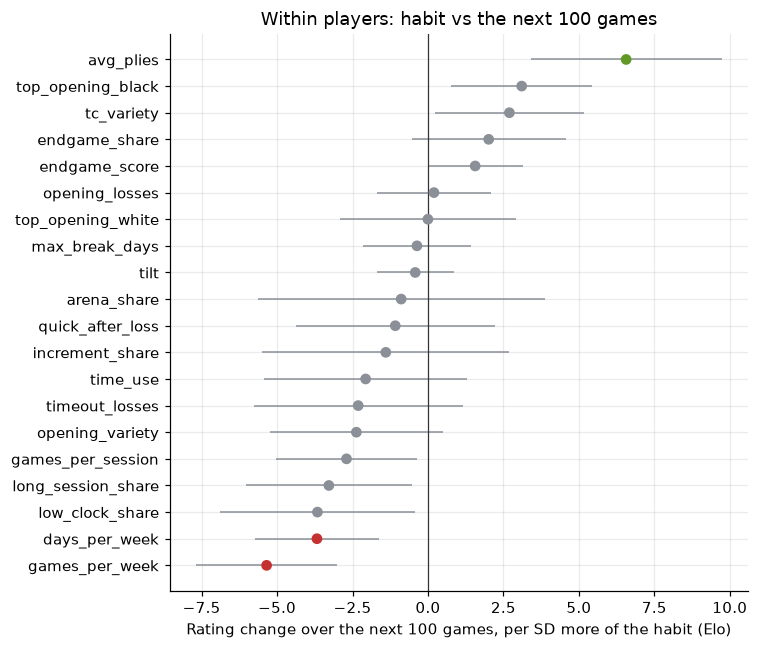

In [15]:
show = WITHIN.sort_values("Elo over next 100 games per SD")
fig, ax = plt.subplots(figsize=(7, 6))
cols = [GREEN if (r_["p (Holm)"] < .05 and r_["Elo over next 100 games per SD"] > 0) else RED if r_["p (Holm)"] < .05 else GREY
        for _, r_ in show.iterrows()]
ax.errorbar(show["Elo over next 100 games per SD"], range(len(show)),
            xerr=[show["Elo over next 100 games per SD"] - show["95% CI low"], show["95% CI high"] - show["Elo over next 100 games per SD"]],
            fmt="none", ecolor=GREY, lw=1)
ax.scatter(show["Elo over next 100 games per SD"], range(len(show)), c=cols, zorder=3)
ax.axvline(0, color="#333", lw=.8)
ax.set_yticks(range(len(show)), show.index)
ax.set(title="Within players: habit vs the next 100 games", xlabel="Rating change over the next 100 games, per SD more of the habit (Elo)")
save("reach-how-within")

**Reading the result.**

- **Between players, volume marks those who get there.** At the same rating and progress, players who later reached 2000 played longer sessions (at game 1,000: 48% of games in sessions of 10+, against 12%) and more games a week (121 vs 59). The effects grow with the checkpoint; long sessions survive the Holm correction at games 300 and 1,000; games a week, days a week, games per session and arena games at game 1,000. They also started the next game within 5 minutes of a loss more often (odds ratio about 1.4 at games 300 and 1,000), which is volume again: how a player *scored* after a loss (tilt) shows nothing. Openings, clock use and endgames show nothing either.
- **Within players, more volume does not help.** When a player plays *more than their own usual* in a stretch of 100 games, the next 100 games go slightly **worse** (about −5 Elo per SD of games per week, −4 per SD of days per week). Stretches with **longer games** (more moves) are followed by slightly better ones (+7 Elo per SD). Playing on quickly after a loss, arenas and session length show nothing after the correction. The effects are small: a few Elo per 100 games.
- **Together:** players who end up at 2000 are the ones who play a lot, but cramming in more games than usual is not what moves the rating. Volume is a sign of commitment, not a lever.
- **Off the board** (snapshot, so association only): players who reached 2000 have done more puzzles (odds ratio about 2 per SD), have a much higher puzzle rating (about 3–3.8, but that is largely the same skill measured twice), have more public studies, and play more bullet, rapid and classical. All are clear after the Holm correction. Whether puzzles *cause* progress, or committed players simply do everything more, this data cannot tell.

## 4. Similar players

For each checkpoint, every player in the model's risk set is kept with their public Lichess username, their inputs at that checkpoint and what happened next. Each player's smoothed rating path is exported too, so the page can draw them next to the user's own. The page finds the players nearest to you on the standardised inputs (start, early trend, current rating, recent trend), and shows the three nearest who reached 2000 and the three nearest who didn't. They are shown in two groups because the sample has every reacher but only about 1 in 9 of the others: a single nearest-neighbour list would show far too many reachers.

In [16]:
SIM = {}
for L, d in LM.items():
    f = FINAL[L]
    cols = [c for c in f["cols"] if c not in TYPE_DUMMIES]
    SIM[L] = {"cols": cols, "rows": [[r.username, *[round(float(getattr(r, c)), 1) for c in cols], int(r.reached),
                                       int(r.held_game) if r.reached else None, int(r.career_games)]
                                      for r in d.itertuples()]}
print({L: len(s["rows"]) for L, s in SIM.items()})

# Rating paths for the "your path and theirs" chart: a smoothed rating on a log-spaced grid of game numbers, from game 30
# to the hold (reachers) or the last downloaded game. Players followed only to game 1,000 get a "tail": their career length
# and blitz rating today, which the page draws as a dotted line (the games in between were not downloaded).
GRID = sorted({int(round(30 * 1.12 ** k)) for k in range(80) if 30 * 1.12 ** k <= 60000})
def path_of(pid):
    g, p = by[pid], P.loc[pid]
    end = int(p.held_game) if p.reached else len(g)
    r = g.rating_after.to_numpy()[:end]
    sm = lambda i: float(r[max(0, i - max(5, i // 8)): i + 1].mean())   # about one grid step back
    pts = [round(sm(x - 1)) for x in GRID if x <= len(r)]
    out = {"r": pts, "end": [len(r), round(sm(len(r) - 1))]}
    u = off.user.get(pid) if pid in off.index else None
    now = ((u or {}).get("perfs", {}).get("blitz") or {}).get("rating") if isinstance(u, dict) else None
    if not p.reached and now and p.career_games > len(g) + 50:
        out["tail"] = [int(p.career_games), int(now)]
    return out
PATHS = {"grid": [x for x in GRID if x <= max(len(g) for g in by.values())],
         "players": {P.loc[pid, "username"]: path_of(pid) for pid in P.index if pid in by and len(by[pid]) >= 40}}
print(f"paths for {len(PATHS['players'])} players, {sum(len(v['r']) for v in PATHS['players'].values()):,} points")

{100: 1115, 200: 1039, 300: 984, 500: 896, 1000: 737}


paths for 1117 players, 35,684 points


## 5. Export for the NeuralGambit dashboard

`reach.json`: for each checkpoint, the logistic model (scaler and coefficients), the isotonic recalibration as breakpoints (the page interpolates between them), the two Weibull models for the remaining games and days, and the similar-player table. A check confirms the exported formulas reproduce the fitted models.

In [17]:
def weib_export(m, cols):
    pr = m.params_
    lam = {c: round(float(pr.loc[("lambda_", c)]), 6) for c in cols + ["Intercept"]}
    return {"cols": cols, "lambda": lam, "log_rho": round(float(pr.loc[("rho_", "Intercept")]), 6)}

# What the page says about "how". Each sentence rests on section 3.
HOW_ADVICE = ("What went with reaching 2000, at the same rating and progress: playing a lot, in long sessions, and, off the "
              "board, more puzzles, studies and other time controls. But when the same player crammed in more games than usual, "
              "the next 100 games went slightly worse, and stretches of longer games went slightly better. So volume marks the "
              "players who get there; it isn't what moves the rating. How players scored after a loss, their openings and their clock use showed nothing.")
export = {"level": LEVEL, "hold_days": HOLD_DAYS, "max_start": 1900, "landmarks": [], "advice": {"general": HOW_ADVICE}}
for L in LANDMARKS:
    f, wb = FINAL[L], WEIB[L]
    sc, lr = f["model"][0], f["model"][-1]
    iso = f["iso"]
    xs, ys = iso.X_thresholds_, iso.y_thresholds_
    d = LM[L]
    export["landmarks"].append({
        "games": L, "recent_n": 100 if "recent_100" in f["cols"] else None,
        "model": {"features": f["cols"], "mean": [round(float(v), 6) for v in sc.mean_], "scale": [round(float(v), 6) for v in sc.scale_],
                  "coef": [round(float(v), 6) for v in lr.coef_[0]], "intercept": round(float(lr.intercept_[0]), 6)},
        "calibration": [[round(float(a), 5), round(float(b), 5)] for a, b in zip(xs, ys)] if f["use_iso"] else [[0, 0], [1, 1]],
        "when_games": weib_export(wb["more_games"]["model"], wb["more_games"]["cols"]),
        "when_days": weib_export(wb["more_days"]["model"], wb["more_days"]["cols"]),
        "similar": SIM[L],
        "meta": {"players": int(len(d)), "reached": int(d.reached.sum()), "rate": round(float(np.average(d.reached, weights=d.weight)), 4),
                 "auc": round(float(f["auc"]), 3), "coverage_games": round(wb["more_games"]["coverage"], 3), "recalibrated": f["use_iso"]},
    })
export["paths"] = PATHS
export["meta"] = {"players": int(len(P)), "games": int(len(full)), "rate": round(float(np.average(y_all, weights=w_all)), 4),
                  "held_game_median": int(R.held_game.median()), "unresolved": int(P.unresolved.sum())}

def predict_export(lm, x):
    m = lm["model"]
    z = sum(c * (x[k] - mu) / s for k, c, mu, s in zip(m["features"], m["coef"], m["mean"], m["scale"])) + m["intercept"]
    p = 1 / (1 + np.exp(-z))
    xs, ys = zip(*lm["calibration"])
    return p, float(np.interp(p, xs, ys))

def weib_median(e, x):
    lam = np.exp(e["lambda"]["Intercept"] + sum(e["lambda"][c] * x[c] for c in e["cols"]))
    return lam * np.log(2) ** (1 / np.exp(e["log_rho"]))

mx = 0
for lm in export["landmarks"]:
    L = lm["games"]; X = design(LM[L], FINAL[L]["cols"])
    raw = FINAL[L]["model"].predict_proba(X)[:, 1]
    mx = max(mx, max(abs(predict_export(lm, X.iloc[i])[0] - raw[i]) for i in range(0, len(X), 25)))
lm = export["landmarks"][2]; wb = WEIB[300]["more_games"]
row = LM[300][LM[300].reached].iloc[0]
xw = {"gap": LEVEL - row.current, "recent": row[WEIB[300]["recent_col"]], "early_trend": row.early_trend}
print(f"max probability difference {mx:.1e}; Weibull median check: {weib_median(lm['when_games'], xw):.1f} vs "
      f"{float(wb['model'].predict_median(pd.DataFrame([xw]))):.1f}")
(OUT / "reach.json").write_text(json.dumps(export, separators=(",", ":")))
APP_STATIC = ROOT.parents[1] / "static" / "plateau"
shutil.copy(OUT / "reach.json", APP_STATIC / "reach.json")
print("wrote", OUT / "reach.json", f"({(OUT / 'reach.json').stat().st_size / 1024:.0f} KB), copied to", APP_STATIC)

max probability difference 2.1e-07; Weibull median check: 2009.4 vs 2009.5


wrote C:\Users\marko\PycharmProjects\Chessmatics\research\plateau\out\reach.json (463 KB), copied to C:\Users\marko\PycharmProjects\Chessmatics\static\plateau


## Summary

- **Will I reach 2000?** For a player below 2000, the best guide at any point is the **current rating**, then the starting rating and early trend; the recent trend and the curve type add almost nothing. One model per checkpoint (100 to 1,000 games) ranks players well (ROC-AUC 0.87–0.92) and gives honest probabilities.
- **When?** Those who got there held 2000 from a median of about game 2,200, roughly a thousand games after first touching it. Most did so within 5,000 games. For a player who will get there, the remaining games can be predicted only to within a factor of about two.
- **How?** Players who reach 2000 play more and in longer sessions, and do more puzzles, studies and other time controls. Within a player, playing more than usual is followed by slightly *worse* results, and longer games by slightly better. No habit in the games is a clear lever; the off-board signals can't be separated from commitment.

**Limits.** One cohort (accounts from late 2020), one site, blitz only. The off-board data is a snapshot taken after the outcome. The controls were sampled, so all rates are weighted back to the cohort. Habits were measured over 100 games before each checkpoint; game phases only up to game 3,000.